# Task 1: Restaurant Rating Prediction

This task focuses on building a machine learning regression model to predict the Aggregate Rating of restaurants using restaurant-related features from the dataset.

## 1. Data Loading and Exploration


In [1]:
import pandas as pd
df=pd.read_csv("Dataset.csv")
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


### 1.1 Dataset Shape

In [2]:
df.shape

(9551, 21)

### 1.2 Dataset Columns

In [3]:
df.columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')

### 1.3 Dataset Information

In [4]:
df.info(
    
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

## 2. Data Preprocessing

In [5]:
df.isnull().sum()

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

### 2.1 Inspecting Missing Values

In [6]:
df[df["Cuisines"].isnull()]

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
84,17284105,Cookie Shoppe,216,Albany,"115 N Jackson St, Albany, GA 31701",Albany,"Albany, Albany",-84.154000,31.577200,NaN,...,Dollar($),No,No,No,No,1,3.4,Orange,Average,34
87,17284211,Pearly's Famous Country Cookng,216,Albany,"814 N Slappey Blvd, Albany, GA 31701",Albany,"Albany, Albany",-84.175900,31.588200,NaN,...,Dollar($),No,No,No,No,1,3.4,Orange,Average,36
94,17284158,Jimmie's Hot Dogs,216,Albany,"204 S Jackson St, Albany, GA 31701",Albany,"Albany, Albany",-84.153400,31.575100,NaN,...,Dollar($),No,No,No,No,1,3.9,Yellow,Good,160
297,17374552,Corkscrew Cafe,216,Gainesville,"51 W Main St, Dahlonega, GA 30533",Dahlonega,"Dahlonega, Gainesville",-83.985800,34.531800,NaN,...,Dollar($),No,No,No,No,3,3.9,Yellow,Good,209
328,17501439,Dovetail,216,Macon,"543 Cherry St, Macon, GA 31201",Macon,"Macon, Macon",-83.627979,32.836410,NaN,...,Dollar($),No,No,No,No,3,3.8,Yellow,Good,102
346,17606621,HI Lite Bar & Lounge,216,Miller,"109 N Broadway Ave, Miller, SD 57362",Miller,"Miller, Miller",-98.989100,44.515800,NaN,...,Dollar($),No,No,No,No,1,3.4,Orange,Average,11
368,17059060,Hillstone,216,Orlando,"215 South Orlando Avenue, Winter Park, FL 32789",Winter Park,"Winter Park, Orlando",-81.365260,28.596682,NaN,...,Dollar($),No,No,No,No,3,4.4,Green,Very Good,1158
418,17142698,Leonard's Bakery,216,Rest of Hawaii,"933 Kapahulu Ave, Honolulu, HI 96816",Kaimuki,"Kaimuki, Rest of Hawaii",-157.813432,21.284586,NaN,...,Dollar($),No,No,No,No,1,4.7,Dark Green,Excellent,707
455,17616465,Tybee Island Social Club,216,Savannah,"1311 Butler Ave, Tybee Island, GA 31328",Tybee Island,"Tybee Island, Savannah",-80.848297,31.995810,NaN,...,Dollar($),No,No,No,No,1,3.9,Yellow,Good,309


### 2.2 Analyzing Missing Cuisine Records

In [7]:
df[df["Cuisines"].isnull()][
["Restaurant Name", "City", "Average Cost for two",
     "Price range", "Aggregate rating", "Votes"]]

,Restaurant Name,City,Average Cost for two,Price range,Aggregate rating,Votes
84,Cookie Shoppe,Albany,0,1,3.4,34
87,Pearly's Famous Country Cookng,Albany,0,1,3.4,36
94,Jimmie's Hot Dogs,Albany,10,1,3.9,160
297,Corkscrew Cafe,Gainesville,40,3,3.9,209
328,Dovetail,Macon,40,3,3.8,102
346,HI Lite Bar & Lounge,Miller,0,1,3.4,11
368,Hillstone,Orlando,40,3,4.4,1158
418,Leonard's Bakery,Rest of Hawaii,10,1,4.7,707
455,Tybee Island Social Club,Savannah,10,1,3.9,309


### 2.3 Handling Missing Values

In [8]:
df["Cuisines"]=df["Cuisines"].fillna("Unknown")
print("Missing values:",df["Cuisines"].isna().sum())
print("Unknown values:",(df["Cuisines"]=="Unknown").sum())

Missing values: 0
Unknown values: 9


### 2.4 Identifying Categorical Features

In [9]:
categorical_columns = df.select_dtypes(include="object").columns

print("Categorical columns:")
print(categorical_columns)

Categorical columns:
Index(['Restaurant Name', 'City', 'Address', 'Locality', 'Locality Verbose',
       'Cuisines', 'Currency', 'Has Table booking', 'Has Online delivery',
       'Is delivering now', 'Switch to order menu', 'Rating color',
       'Rating text'],
      dtype='object')


### 2.5 Checking Unique Values

In [10]:
df.nunique().sort_values()

Switch to order menu       1
Is delivering now          2
Has Online delivery        2
Has Table booking          2
Price range                4
Rating color               6
Rating text                6
Currency                  12
Country Code              15
Aggregate rating          33
Average Cost for two     140
City                     141
Votes                   1012
Locality                1208
Locality Verbose        1265
Cuisines                1826
Restaurant Name         7446
Longitude               8120
Latitude                8677
Address                 8918
Restaurant ID           9551
dtype: int64

### 2.6 Correlation Analysis

In [11]:
df.select_dtypes(include=["int64", "float64"]).corr()["Aggregate rating"].sort_values(ascending=False)

Aggregate rating        1.000000
Price range             0.437944
Votes                   0.313691
Country Code            0.282189
Average Cost for two    0.051792
Latitude                0.000516
Longitude              -0.116818
Restaurant ID          -0.326212
Name: Aggregate rating, dtype: float64

### 2.7 Separating Features and Target

In [12]:
X = df.drop("Aggregate rating", axis=1)
y = df["Aggregate rating"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (9551, 20)
Target shape: (9551,)


### 2.8 Analyzing Target-Related Features

In [13]:
print(df["Switch to order menu"].value_counts())

Switch to order menu
No    9551
Name: count, dtype: int64


In [14]:
print(df["Rating text"].value_counts())

Rating text
Average      3737
Not rated    2148
Good         2100
Very Good    1079
Excellent     301
Poor          186
Name: count, dtype: int64


In [15]:
print(df["Rating color"].value_counts())

Rating color
Orange        3737
White         2148
Yellow        2100
Green         1079
Dark Green     301
Red            186
Name: count, dtype: int64


### 2.9 Analyzing Locality Features

In [16]:
print(df[["Locality", "Locality Verbose"]].head(10))

                                          Locality  \
0        Century City Mall, Poblacion, Makati City   
1       Little Tokyo, Legaspi Village, Makati City   
2       Edsa Shangri-La, Ortigas, Mandaluyong City   
3           SM Megamall, Ortigas, Mandaluyong City   
4           SM Megamall, Ortigas, Mandaluyong City   
5           SM Megamall, Ortigas, Mandaluyong City   
6  SM by the Bay, Mall of Asia Complex, Pasay City   
7  SM by the Bay, Mall of Asia Complex, Pasay City   
8      Sofitel Philippine Plaza Manila, Pasay City   
9                                        Kapitolyo   

                                    Locality Verbose  
0  Century City Mall, Poblacion, Makati City, Mak...  
1  Little Tokyo, Legaspi Village, Makati City, Ma...  
2  Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...  
3  SM Megamall, Ortigas, Mandaluyong City, Mandal...  
4  SM Megamall, Ortigas, Mandaluyong City, Mandal...  
5  SM Megamall, Ortigas, Mandaluyong City, Mandal...  
6  SM by the Bay, Ma

In [17]:
print(df[["Locality", "Locality Verbose"]].nunique())

Locality            1208
Locality Verbose    1265
dtype: int64


## 3. Feature Selection

In [18]:
columns_to_drop = [
    "Restaurant ID",
    "Switch to order menu",
    "Rating text",
    "Rating color"
]

X = df.drop(columns=columns_to_drop + ["Aggregate rating"])
y = df["Aggregate rating"]

print("Features:", X.shape)
print("Target:", y.shape)
print("Remaining columns:")
print(X.columns.tolist())

Features: (9551, 16)
Target: (9551,)
Remaining columns:
['Restaurant Name', 'Country Code', 'City', 'Address', 'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Price range', 'Votes']


### 3.1 Identifying Numerical and Categorical Features

In [19]:
numerical_columns = X.select_dtypes(include=["int64", "float64"]).columns
categorical_columns = X.select_dtypes(include=["object"]).columns

print("Numerical columns:")
print(numerical_columns.tolist())

print("\nCategorical columns:")
print(categorical_columns.tolist())

Numerical columns:
['Country Code', 'Longitude', 'Latitude', 'Average Cost for two', 'Price range', 'Votes']

Categorical columns:
['Restaurant Name', 'City', 'Address', 'Locality', 'Locality Verbose', 'Cuisines', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now']


### 3.2 Checking Categorical Feature Cardinality

In [20]:
for col in categorical_columns:
    print(f"{col}: {X[col].nunique()} unique values")

Restaurant Name: 7446 unique values
City: 141 unique values
Address: 8918 unique values
Locality: 1208 unique values
Locality Verbose: 1265 unique values
Cuisines: 1826 unique values
Currency: 12 unique values
Has Table booking: 2 unique values
Has Online delivery: 2 unique values
Is delivering now: 2 unique values


### 3.3 Removing High-Cardinality Features

In [21]:
columns_to_remove = [
    "Restaurant Name",
    "Address",
    "Locality",
    "Locality Verbose",
    "Cuisines"
]

X = X.drop(columns=columns_to_remove)

print("Features shape:", X.shape)
print("\nRemaining columns:")
print(X.columns.tolist())

Features shape: (9551, 11)

Remaining columns:
['Country Code', 'City', 'Longitude', 'Latitude', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Price range', 'Votes']


### 3.4 Final Feature Selection

In [22]:
print(X.columns.tolist())

['Country Code', 'City', 'Longitude', 'Latitude', 'Average Cost for two', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Price range', 'Votes']


## 4. Feature Encoding and Preprocessing

In [23]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "Country Code",
    "City",
    "Currency",
    "Has Table booking",
    "Has Online delivery",
    "Is delivering now"
]

numerical_features = [
    "Longitude",
    "Latitude",
    "Average Cost for two",
    "Price range",
    "Votes"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


## 5. Train-Test Split

In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (7640, 11)
X_test: (1911, 11)
y_train: (7640,)
y_test: (1911,)


### 5.1 Applying Data Preprocessing

In [25]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed X_train shape:", X_train_processed.shape)
print("Processed X_test shape:", X_test_processed.shape)

Processed X_train shape: (7640, 165)
Processed X_test shape: (1911, 165)


## 6. Model Building

In [26]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

print("Linear Regression model created successfully.")

Linear Regression model created successfully.


### 6.1 Training Linear Regression Model

In [27]:
model.fit(X_train_processed, y_train)

print("Model trained successfully.")

Model trained successfully.


### 6.2 Making Predictions with Linear Regression

In [28]:
y_pred = model.predict(X_test_processed)

print(y_pred[:10])

[1.94763098 3.20438873 1.85442873 2.84175547 1.92810563 1.92101872
 2.77081164 1.96094625 2.33362415 3.17503027]


### 6.3 Evaluating Linear Regression

In [29]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)
print("R² Score:", r2)

Mean Squared Error: 1.521562182817232
R² Score: 0.3315073270676969


### 6.4 Decision Tree Regression

In [30]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(random_state=42)

print("Decision Tree Regressor created.")

Decision Tree Regressor created.


### 6.6 Making Predictions with Decision Tree

In [31]:
tree_model.fit(X_train_processed, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [32]:
y_tree_pred = tree_model.predict(X_test_processed)

print(y_tree_pred[:10])

[3.9 4.  2.6 4.3 3.1 0.  3.  0.  3.5 3.5]


### 6.7 Evaluating Decision Tree

In [33]:
from sklearn.metrics import mean_squared_error, r2_score

tree_mse = mean_squared_error(y_test, y_tree_pred)
tree_r2 = r2_score(y_test, y_tree_pred)

print("Decision Tree MSE:", tree_mse)
print("Decision Tree R²:", tree_r2)

Decision Tree MSE: 0.19875457875457872
Decision Tree R²: 0.9126779167426626


## 7. Feature Importance Analysis

In [34]:
feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.Series(
    tree_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print(feature_importance.head(10))

num__Votes                          0.948447
num__Longitude                      0.022229
num__Latitude                       0.014577
num__Average Cost for two           0.008132
cat__Currency_Brazilian Real(R$)    0.000810
num__Price range                    0.000726
cat__Has Online delivery_No         0.000590
cat__Has Online delivery_Yes        0.000546
cat__Has Table booking_No           0.000380
cat__City_New Delhi                 0.000270
dtype: float64


## 8. Overfitting Analysis

In [35]:
y_train_pred = tree_model.predict(X_train_processed)

train_mse = mean_squared_error(y_train, y_train_pred)
train_r2 = r2_score(y_train, y_train_pred)

print("Train MSE:", train_mse)
print("Train R²:", train_r2)
print("Test MSE:", tree_mse)
print("Test R²:", tree_r2)

Train MSE: 1.8324607329842937e-05
Train R²: 0.9999920491038256
Test MSE: 0.19875457875457872
Test R²: 0.9126779167426626


## 9. Model Tuning

In [36]:
for depth in [5, 10, 15]:
    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )
    
    model.fit(X_train_processed, y_train)
    
    predictions = model.predict(X_test_processed)
    
    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)
    
    print(f"Max Depth: {depth}")
    print(f"Test MSE: {mse:.4f}")
    print(f"Test R²: {r2:.4f}")
    print("-" * 30)

Max Depth: 5
Test MSE: 0.1066
Test R²: 0.9532
------------------------------
Max Depth: 10
Test MSE: 0.1117
Test R²: 0.9509
------------------------------
Max Depth: 15
Test MSE: 0.1496
Test R²: 0.9343
------------------------------


## 10. Final Model Selection

In [37]:
final_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)

final_model.fit(X_train_processed, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


## 11. Final Feature Importance Analysis

In [38]:
final_feature_importance = pd.Series(
    final_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print(final_feature_importance.head(10))

num__Votes                          0.986028
num__Longitude                      0.009159
num__Latitude                       0.003962
cat__Currency_Brazilian Real(R$)    0.000851
cat__City_Puducherry                0.000000
cat__City_Paynesville               0.000000
cat__City_Penola                    0.000000
cat__City_Pensacola                 0.000000
cat__City_Pocatello                 0.000000
cat__City_Potrero                   0.000000
dtype: float64


## 12. Actual vs Predicted Visualization

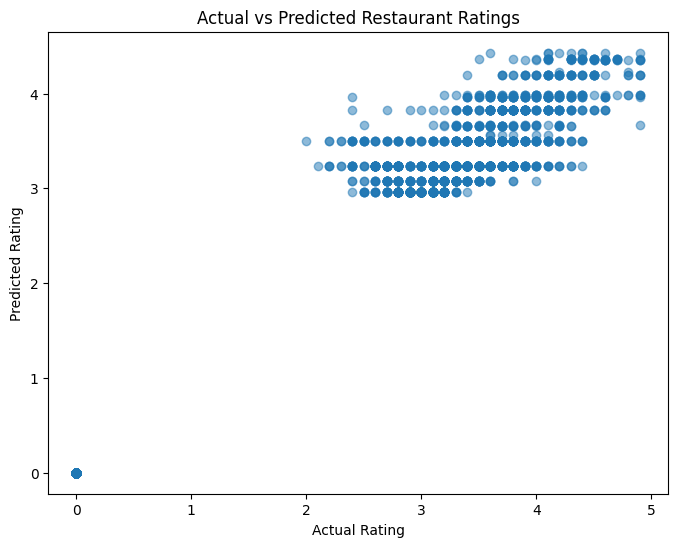

In [39]:
import matplotlib.pyplot as plt

final_predictions = final_model.predict(X_test_processed)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, final_predictions, alpha=0.5)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Restaurant Ratings")

plt.show()

## 13. Results and Interpretation

The Decision Tree Regressor performed better than Linear Regression on the test dataset. After tuning the tree depth, max_depth=5 achieved the best performance with an MSE of approximately 0.1066 and an R² score of approximately 0.9532. The feature importance analysis showed that Votes was the most influential feature in the final model.

## 14. Conclusion

A complete machine learning regression workflow was developed to predict restaurant Aggregate Ratings. The dataset was explored and preprocessed, categorical features were encoded, regression models were trained and evaluated, and the Decision Tree was tuned to reduce overfitting. The final model achieved strong predictive performance on the test dataset.